In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
file_path = r"my_robot_data\data\chunk-000\cleaned_data.parquet"
df = pd.read_parquet(file_path)

In [4]:
ep_id=2
ep_data=df[df['episode_index'] ==ep_id].copy()

In [5]:
ep_data['action_x']=ep_data['action'].apply(lambda x: x[0])

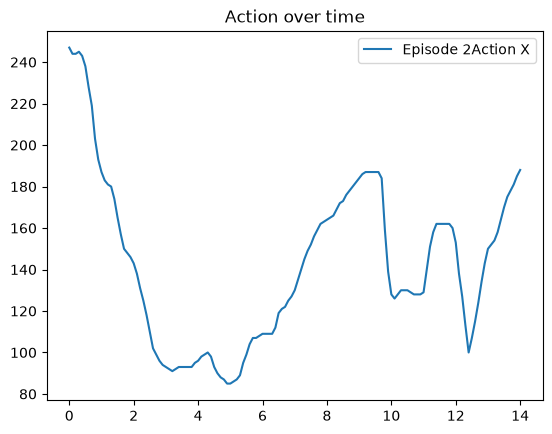

In [ ]:
plt.Figure(figsize=(10,4))
plt.plot(ep_data['timestamp'],
         ep_data['action_x'],label=f'Episode {ep_id}Action X')
plt.title("Action over time")
plt.legend()
plt.show()

In [16]:
ep_data['dx']=ep_data['action_x'].diff().abs()
idle_threshold=0.5
moving_frames=ep_data[ep_data['dx']>idle_threshold]
start_time = moving_frames['timestamp'].min()
end_time=moving_frames['timestamp'].max()

print(f"整个片段有多长：{ep_data['timestamp'].min()}到{ep_data['timestamp'].max()}")
print(f"真正有效动作从：{start_time}开始")
print(f"真正有效动作到：{end_time}结束")

整个片段有多长：0.0到14.0
真正有效动作从：0.10000000149011612开始
真正有效动作到：14.0结束


In [ ]:
def trim_idle_frames(episode_df,idle_threshold=0.5):
    if len(episode_df)==0:
        return episode_df
    action_x=episode_df['action'].apply(lambda x: x[0])
    dx=action_x.diff().abs()
    active_indices=episode_df.index[dx>idle_threshold]

    if len(active_indices)==0:
        return episode_df.iloc[0:0]
    start_idx=active_indices[0]
    end_idx=active_indices[-1]

    start_loc=episode_df.index.get_loc(start_idx)
    end_loc=episode_df.index.get_loc(end_idx)

    final_start=max(0, start_loc - 5)
    flnal_end=min(len(episode_df),end_loc+6)

    return
episode_df.iloc[final_start:final_end]

print("正在切割数据...")
golden_df=df